# MathArena

Exploratory analysis of the `matharena` build of measurement-db, and the evidence behind the decisions in `scripts/preprocess/matharena.py`. Outputs show counts and distributions only: item text and model solutions are not printed (gated dataset).

## 1. Setup

In [1]:
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import json
import re
import warnings
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "scripts" / "preprocess"))
REPO = "aims-foundations/measurement-db"
B = "matharena"
REVISION = HfApi().dataset_info(REPO).sha  # pinned for the whole notebook, as the preprocessing scripts do

warnings.filterwarnings("ignore", message=".*symlink.*")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
print("measurement-db revision:", REVISION)

measurement-db revision: 54074453da7b9911be0f48e4c560be547bc84d21


In [2]:
# Plot style (same palette as the other analysis notebooks): blue = success, orange = failure.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e1"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9.5,
})


def load(table, columns=None):
    """One formatted table at the pinned revision."""
    path = hf_hub_download(REPO, f"{B}/formatted_tables/{table}.parquet", repo_type="dataset", revision=REVISION)
    return pd.read_parquet(path, columns=columns)


def load_yaml(name):
    return yaml.safe_load(open(hf_hub_download(REPO, f"{B}/{name}", repo_type="dataset", revision=REVISION),
                               encoding="utf-8"))


def kv(s):
    """Parse 'k=v;k=v' into a dict."""
    return dict(p.split("=", 1) for p in s.split(";") if "=" in p) if isinstance(s, str) else {}


def null_report(df):
    return pd.DataFrame({"null_share": df.isna().mean().round(3), "distinct": df.nunique()})


def panels(n, width=5.2, height=3.4):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), squeeze=False)
    return fig, axes[0]


def show(fig):
    fig.tight_layout()
    plt.show()


def barh(ax, series, title, xlabel, color=BLUE, fmt="{:.2f}"):
    s = series[::-1]
    ax.barh([str(i) for i in s.index], s.values, color=color, height=0.65)
    for y, v in enumerate(s.values):
        ax.annotate(fmt.format(v), (v, y), xytext=(3, 0), textcoords="offset points", va="center",
                    fontsize=7.5, color=INK2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

## 2. Metadata and provenance

In [3]:
bench = load("benchmarks").iloc[0]
meta, char = load_yaml("metadata.yaml"), load_yaml("characterization.yaml")
print(textwrap.fill(bench.description, 120), "\n")
print("testing_condition:\n" + textwrap.fill(meta["benchmark"]["testing_condition"], 120), "\n")
display(bench[["name", "response_type", "multi_single_turn", "modality", "n_subjects", "n_items", "n_responses",
               "max_trial", "coverage", "release_date", "license"]].to_frame("value"))
print(f"{len(meta['sources']['upstream'])} upstream output datasets (one per competition release)")

MathArena scores models on problems from recent mathematics competitions, checking the final answer where there is one
and having judges grade written proofs criterion by criterion where the problem asks for a proof. 

testing_condition:
One released attempt per trial; proof judges and criteria are item verifiers, not test conditions. No unrecorded
inference conditions are supplied. 



,value
name,MathArena
response_type,mixed
multi_single_turn,"multi_turn, single_turn"
modality,"[text, image]"
n_subjects,104
n_items,1755
n_responses,92944
max_trial,200
coverage,0.111517
release_date,2025-05


28 upstream output datasets (one per competition release)


In [4]:
tables = {t: load(t) for t in ["items", "subjects", "responses"]}
traces = load("traces", columns=["response_id", "trace"])
display(pd.DataFrame({
    "declared_rows": {t: v["rows"] for t, v in char["tables"].items()},
    "actual_rows": {**{t: len(df) for t, df in tables.items()}, "traces": len(traces), "benchmarks": 1,
                    "assets": None},
}))
items, subjects, resp = tables["items"], tables["subjects"], tables["responses"]

,declared_rows,actual_rows
assets,168,NaN
benchmarks,1,1.0
items,1755,1755.0
responses,92944,92944.0
subjects,104,104.0
traces,90005,90005.0


- Row counts match `characterization.yaml` for every table read here.
- Scores are mixed: a provider verdict (0/1) for final-answer problems, criterion points / max points for proofs.
  One released attempt is one trial.

## 3. Subjects

In [5]:
print(f"{len(subjects)} subjects · distinct display_name: {subjects.display_name.nunique()} · "
      f"distinct normalized_name: {subjects.normalized_name.nunique()}")
display(null_report(subjects.drop(columns="subject_id")))
extra = pd.DataFrame(subjects.subject_features_extra.map(kv).tolist())
print("subject_features_extra keys:", list(extra.columns))

104 subjects · distinct display_name: 104 · distinct normalized_name: 45


,null_share,distinct
display_name,0.000,104
normalized_name,0.500,45
provider,0.500,14
release_date,0.500,39
access_date,1.000,0
harness,1.000,0
reasoning_effort,0.702,5
harness_version,1.000,0
subject_features_extra,0.000,104


subject_features_extra keys: ['model_config', 'source_model_name']


In [6]:
# What the display names encode: reasoning effort, thinking mode, dated snapshots, agent setups.
name = subjects.display_name
flags = pd.DataFrame({
    "effort suffix (low…max)": name.str.contains(r"\((?:low|medium|high|xhigh|max)\)", case=False),
    "thinking marker": name.str.contains(r"think|reasoning", case=False),
    "agent setup": name.str.contains(r"\bagent\b", case=False),
    "dated snapshot": name.str.contains(r"\d{2}-\d{2}|\d{4}|\(\d{2}/\d{2}\)"),
})
blank = subjects.normalized_name.isna()
display(pd.DataFrame({"all subjects": flags.sum(), "blank normalized_name": flags[blank].sum()}))
print("reasoning_effort filled:", subjects.reasoning_effort.notna().sum(),
      "· effort suffix in name:", flags.iloc[:, 0].sum())

,all subjects,blank normalized_name
effort suffix (low…max),31,18
thinking marker,23,14
agent setup,4,4
dated snapshot,7,4


reasoning_effort filled: 31 · effort suffix in name: 31


In [7]:
# After filling the blank names (NAMES in the preprocessing script): how many base models, and how many
# configurations per base model?
from matharena import NAMES
filled = subjects.normalized_name.fillna(subjects.display_name.map(NAMES))
print(f"blank names covered by NAMES: {subjects.display_name[blank].isin(NAMES).all()} · "
      f"base models after filling: {filled.nunique()}")
per_model = filled.value_counts()
print("configurations per base model:", per_model.value_counts().sort_index().to_dict())
display(per_model[per_model >= 3].rename("configurations").to_frame())

blank names covered by NAMES: True · base models after filling: 79
configurations per base model: {1: 61, 2: 13, 3: 4, 5: 1}


,configurations
normalized_name,
Google Gemini 2.5 Pro,5
OpenAI GPT-5.2,3
OpenAI o3-mini,3
OpenAI o4-mini,3
Google Gemini 3.1 Pro,3


In [8]:
# Overlap with the other benchmarks of the bank, by normalized_name.
others = {}
for b in ["mmdocrag", "multi_swebench", "real_webagents", "researchcodebench", "swe_rebench"]:
    p = hf_hub_download(REPO, f"{b}/formatted_tables/subjects.parquet", repo_type="dataset", revision=REVISION)
    others[b] = set(pd.read_parquet(p).normalized_name.dropna())
models = set(filled)
overlap = pd.Series({b: len(models & s) for b, s in others.items()}, name="shared base models")
display(overlap.to_frame())
print(f"MathArena base models seen in at least one other benchmark: {len(models & set().union(*others.values()))} "
      f"of {len(models)}")

,shared base models
mmdocrag,18
multi_swebench,13
real_webagents,17
researchcodebench,15
swe_rebench,0


MathArena base models seen in at least one other benchmark: 30 of 79


- **Half the subjects (52 of 104) have no `normalized_name`, `provider` or `release_date`.** Their identity is
  only in `display_name` (and `model_config` in the extras).
- The display name encodes the configuration: 31 subjects carry an effort suffix, and exactly these 31 have
  `reasoning_effort` filled. 4 are MathArena agent setups and a few are dated snapshots.
- After filling the blank names, the 104 subjects are **79 base models**; 18 of them appear in 2–5
  configurations (Gemini 2.5 Pro in 5).
- Only 30 of the 79 base models appear in another benchmark of the bank. For the rest, the assessor can only
  relate them to other subjects through subject features, so filling those fields matters (decision D3).

## 4. Items

In [9]:
feats = pd.DataFrame(items.item_features.map(kv).tolist(), index=items.index)
items = items.assign(
    competition=feats.competition,
    verifier=items.verifier.map(lambda v: json.loads(v)["class"]),
    has_image=items.asset_manifest.notna(),
    chars=items.content.str.len(),
)
print(f"{len(items):,} items · item_id unique: {items.item_id.is_unique} · raw_item_id unique: "
      f"{items.raw_item_id.is_unique} ({items.raw_item_id.nunique():,} distinct)")
print("verifier:", items.verifier.value_counts().to_dict(), "· with images:", items.has_image.sum())
comp = items.groupby("competition").agg(items=("item_id", "size"), problems=("raw_item_id", "nunique"),
                                        judge=("verifier", lambda v: (v == "judge").sum()),
                                        images=("has_image", "sum"))
display(comp.sort_values("items", ascending=False))

1,755 items · item_id unique: True · raw_item_id unique: False (680 distinct)
verifier: {'exact_matcher': 1484, 'judge': 271} · with images: 336


,items,problems,judge,images
competition,,,,
cmimc_2025,209,40,0,0
smt_2025,168,53,0,0
aime_2025,155,30,0,0
imo_2025,141,6,141,0
apex_shortlist,114,48,0,0
hmmt_feb_2025,94,30,0,0
brumo_2025,93,30,0,0
hmmt_nov_2025,61,30,0,0
kangaroo_2025_9_10,60,30,0,60


In [10]:
# Why raw_item_id repeats: proof criteria, and problems whose prompt differs between model configurations.
grp = items.groupby("raw_item_id").agg(n=("item_id", "size"), verifier=("verifier", "first"),
                                       prompts=("content_hash", "nunique"))
rep = grp[grp.n > 1]
print(f"raw_item_ids with several items: {len(rep)} ({rep.n.sum():,} items)")
print("  proof problems (judge), criteria per problem:", rep[rep.verifier == "judge"].n.value_counts().sort_index().to_dict())
print("  final-answer problems, prompt variants per problem:",
      rep[rep.verifier == "exact_matcher"].prompts.value_counts().sort_index().to_dict())
crit = items[items.verifier == "judge"].grading_criterion.map(lambda g: json.loads(json.loads(g)["rule"]))
print("proof criterion max_points:", crit.map(lambda c: c.get("max_points")).value_counts().sort_index().to_dict())
fa_items = items[items.verifier == "exact_matcher"]
seen = resp.drop_duplicates(["subject_id", "item_id"]).merge(fa_items[["item_id", "raw_item_id"]], on="item_id")
k = seen.groupby(["subject_id", "raw_item_id"]).item_id.nunique()
print(f"(subject, final-answer problem) pairs that saw more than one prompt variant: {(k > 1).sum()} of {len(k):,}")

raw_item_ids with several items: 494 (1,569 items)
  proof problems (judge), criteria per problem: {2: 12, 4: 6, 5: 3, 6: 4, 8: 3, 10: 1, 16: 2, 24: 1, 25: 2, 35: 1}
  final-answer problems, prompt variants per problem: {1: 168, 2: 74, 3: 130, 4: 30, 5: 33, 6: 21, 7: 3}
proof criterion max_points: {1: 151, 2: 52, 3: 36, 4: 6, 5: 2, 10: 24}
(subject, final-answer problem) pairs that saw more than one prompt variant: 23 of 19,296


content_hash values shared by several competitions: 109 (735 items)


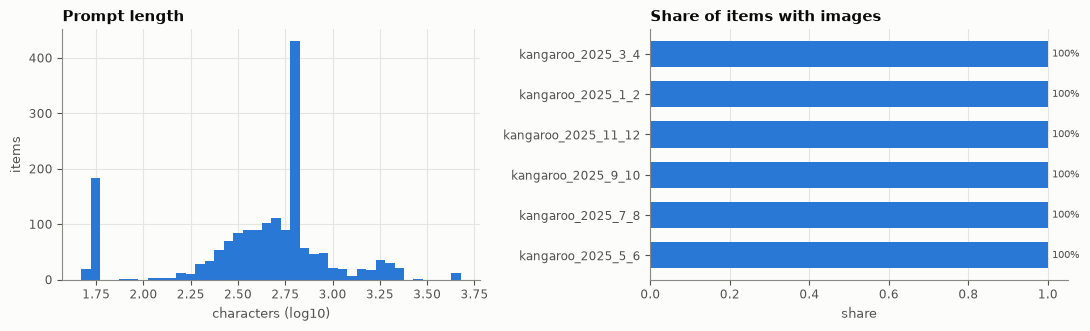

In [11]:
# The same problem text across competition releases (e.g. aime_2025 and aime_2025_I).
by_hash = items.groupby("content_hash").competition.nunique()
print(f"content_hash values shared by several competitions: {(by_hash > 1).sum()} "
      f"({items.content_hash.isin(by_hash.index[by_hash > 1]).sum()} items)")
fig, axes = panels(2, width=5.5)
axes[0].hist(np.log10(items.chars), bins=40, color=BLUE)
axes[0].set_title("Prompt length")
axes[0].set_xlabel("characters (log10)")
axes[0].set_ylabel("items")
comp_share = items.groupby("competition").has_image.mean().sort_values()
barh(axes[1], comp_share[comp_share > 0], "Share of items with images", "share", fmt="{:.0%}")
show(fig)

- **1,755 items, but only 680 distinct problems.** Two reasons a `raw_item_id` repeats:
  - proof problems (IMO, IMC, USAMO, Putnam, Miklós: 271 items) are split into their grading criteria, 2 to 35
    per problem;
  - final-answer problems appear under up to 7 prompt wordings, one per model configuration. A subject
    almost never sees two wordings of the same problem (23 of ~19k pairs), so these items do not split one
    subject's evidence.

  `raw_item_id` is therefore not a key; the final item_id adds the build id where it repeats (D1).
- **109 problem texts recur across competition releases** (735 items, e.g. `aime_2025` vs `aime_2025_I`). An
  item-level split leaks across them: group by `content_hash` when splitting.
- Images are only in the Kangaroo competitions (336 items, all of them). They go into the question as
  `<image:PATH>` markers, as for MMDocRAG.

## 5. Responses

In [12]:
print(f"{len(resp):,} responses · missing scores: {resp.response.isna().sum()} · "
      f"test_condition / interactors all null: {resp.test_condition.isna().all()}, {resp.interactors.isna().all()}")
print("duplicate (subject, item, trial):", resp.duplicated(["subject_id", "item_id", "trial"]).sum())
r = resp.merge(items[["item_id", "competition", "verifier"]], on="item_id")
pairs = r.groupby(["subject_id", "item_id"]).agg(n=("response", "size"), score=("response", "mean"),
                                                  verifier=("verifier", "first"), competition=("competition", "first"))
print(f"{len(pairs):,} (subject, item) pairs · attempts per pair:", pairs.n.value_counts().sort_index().to_dict())
print("coverage of the subject × item grid:", f"{len(pairs) / (subjects.shape[0] * len(items)):.1%}")
display(r.groupby("verifier").response.describe().round(3))

92,944 responses · missing scores: 0 · test_condition / interactors all null: True, True
duplicate (subject, item, trial): 0
20,354 (subject, item) pairs · attempts per pair: {1: 253, 2: 12, 3: 36, 4: 18981, 7: 1, 8: 461, 12: 1, 14: 1, 15: 1, 16: 502, 28: 1, 31: 1, 32: 94, 200: 9}
coverage of the subject × item grid: 11.2%


,count,mean,std,min,25%,50%,75%,max
verifier,,,,,,,,
exact_matcher,89482.0,0.671,0.470,0.0,0.0,1.0,1.0,1.0
judge,3462.0,0.199,0.394,0.0,0.0,0.0,0.0,1.0


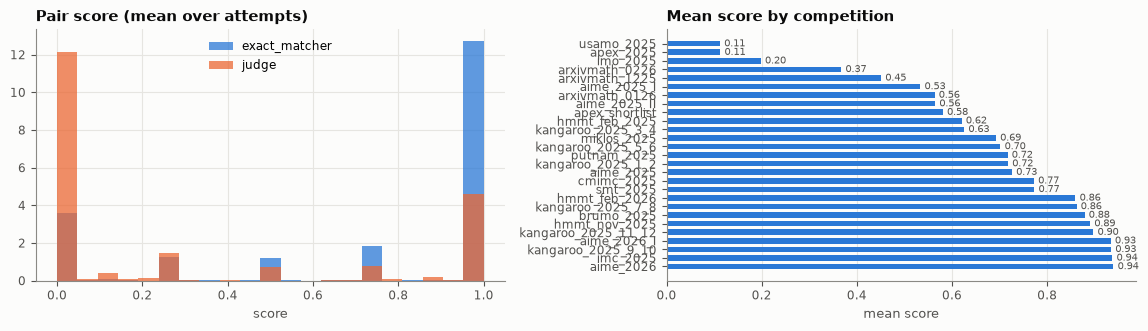

In [13]:
fig, axes = panels(2, width=5.8)
for v, color in [("exact_matcher", BLUE), ("judge", ORANGE)]:
    axes[0].hist(pairs.score[pairs.verifier == v], bins=21, color=color, alpha=0.75, label=v, density=True)
axes[0].legend()
axes[0].set_title("Pair score (mean over attempts)")
axes[0].set_xlabel("score")
rate = r.groupby("competition").response.mean().sort_values()
barh(axes[1], rate, "Mean score by competition", "mean score")
show(fig)

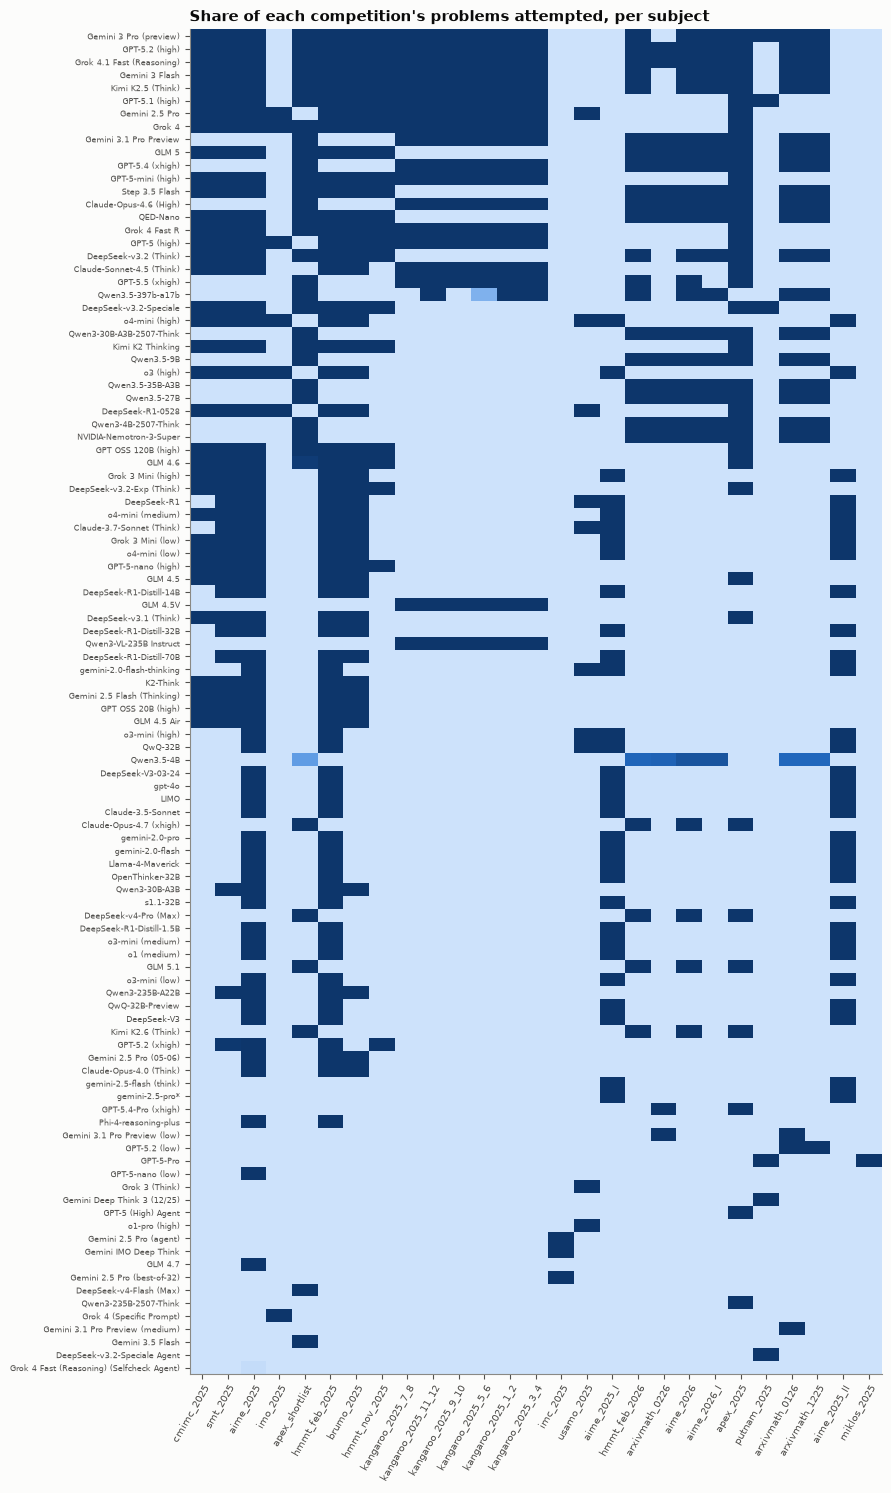

competitions attempted per subject: {'count': 104.0, 'mean': 6.6, 'std': 4.9, 'min': 1.0, '25%': 4.0, '50%': 5.0, '75%': 8.0, 'max': 20.0}


In [14]:
# Who answered what: subjects × competitions (share of the competition's problems attempted).
lab = subjects.set_index("subject_id").display_name
raw = items.set_index("item_id").raw_item_id
cov = (pairs.reset_index().assign(problem=lambda d: d.item_id.map(raw))
       .groupby(["subject_id", "competition"]).problem.nunique().unstack(fill_value=0) / comp["problems"])
cov.index = cov.index.map(lab)
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).index, comp.sort_values("items").index[::-1]]
fig, ax = plt.subplots(figsize=(9, 0.13 * len(cov) + 1.5))
ax.imshow(cov.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(cov.shape[1]), cov.columns, rotation=60, ha="right", rotation_mode="anchor", fontsize=7)
ax.set_yticks(range(cov.shape[0]), cov.index, fontsize=5.5)
ax.grid(False)
ax.set_title("Share of each competition's problems attempted, per subject")
show(fig)
print("competitions attempted per subject:", (cov > 0).sum(axis=1).describe().round(1).to_dict())

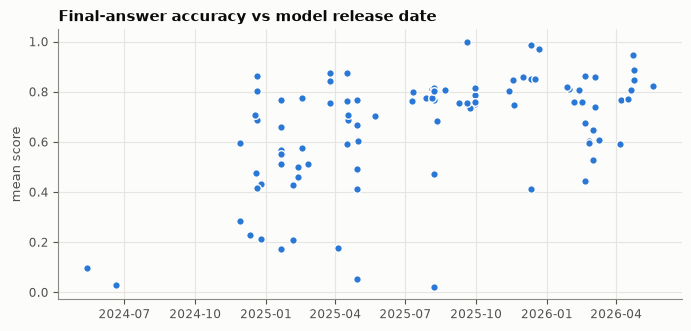

Spearman(release date, accuracy) = +0.48 over 95 subjects


In [15]:
# Model strength vs release date (subjects with a known date, final-answer items only).
filled_by_id = pd.Series(filled.values, index=subjects.subject_id)
curated = yaml.safe_load(open(ROOT / "scripts" / "preprocess" / "models.yaml", encoding="utf-8"))
release = subjects.set_index("subject_id").release_date.fillna(
    filled_by_id.map(lambda n: (curated.get(n) or {}).get("release_date")))
s = (pairs[pairs.verifier == "exact_matcher"].groupby("subject_id").score.mean().to_frame("rate")
     .join(pd.to_datetime(release, errors="coerce").rename("release")).dropna())
fig, axes = panels(1, width=7)
axes[0].scatter(s.release, s.rate, s=30, color=BLUE, edgecolor=SURFACE)
axes[0].set_title("Final-answer accuracy vs model release date")
axes[0].set_ylabel("mean score")
show(fig)
print(f"Spearman(release date, accuracy) = {s.release.rank().corr(s.rate.rank()):+.2f} over {len(s)} subjects")

- 20,354 (subject, item) pairs, most with 4 attempts; a few configurations have 8–32, and 2 subjects
  have 200 attempts on a handful of items.
- **Coverage is 11% of the grid, and it is structured**: each subject attempts a median of 5 competitions, and
  recent models face the 2026 competitions while older models face the 2025 ones. Model strength and
  competition difficulty are confounded (accuracy vs release date: Spearman +0.48).
- Final-answer items average 0.67. Proof criteria average 0.20 and are mostly 0: their scale differs from
  final-answer items, a reason to keep `eval_type` as an item feature.

## 6. Failed attempts: empty solutions

`traces` holds each attempt's released solution text.

In [16]:
sol = resp.response_id.map(traces.set_index("response_id").trace)
r["has_trace"] = sol.notna().values
r["empty_sol"] = (sol.notna() & sol.str.strip().isin(["", "None", "null"])).values
r["chars"] = sol.str.len().values
print("attempts without a trace, by verifier:", r[~r.has_trace].verifier.value_counts().to_dict())
judge = r[r.verifier == "judge"].merge(items[["item_id", "raw_item_id"]], on="item_id")
first = judge.groupby(["subject_id", "raw_item_id", "trial"]).has_trace.sum()
print("proof attempts (subject, problem, trial) with exactly one traced criterion:", f"{(first == 1).mean():.1%}")
emp = r[r.empty_sol]
print(f"\nattempts with an empty solution: {len(emp)} · their mean score: {emp.response.mean():.3f}")
display(emp.groupby(emp.subject_id.map(lab)).agg(attempts=("response", "size"), mean_score=("response", "mean"),
                                                   competitions=("competition", "nunique"))
        .sort_values("attempts", ascending=False))

attempts without a trace, by verifier: {'judge': 2939}
proof attempts (subject, problem, trial) with exactly one traced criterion: 100.0%

attempts with an empty solution: 140 · their mean score: 0.014


,attempts,mean_score,competitions
subject_id,,,
Claude-Opus-4.7 (xhigh),119,0.0,4
Kimi K2.6 (Think),9,0.0,3
GLM 5,4,0.0,4
GPT-5.4-Pro (xhigh),2,0.0,1
Kimi K2.5 (Think),2,0.0,1
Qwen3.5-397b-a17b,2,1.0,1
Step 3.5 Flash,2,0.0,2


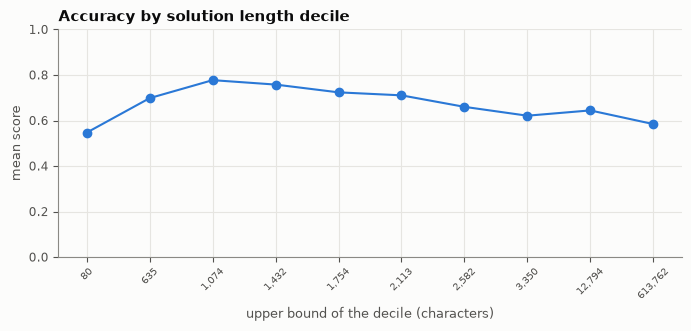

In [17]:
# Long solutions: output length and score (final-answer items). Very long outputs often hit the token limit.
fa = r[(r.verifier == "exact_matcher") & r.has_trace & ~r.empty_sol]
bins = pd.qcut(np.log10(fa.chars + 1), 10)
g = fa.groupby(bins, observed=True).response.mean()
fig, axes = panels(1, width=7)
axes[0].plot(range(len(g)), g.values, marker="o", color=BLUE)
axes[0].set_xticks(range(len(g)), [f"{10 ** iv.right:,.0f}" for iv in g.index], rotation=45, fontsize=7)
axes[0].set_title("Accuracy by solution length decile")
axes[0].set_xlabel("upper bound of the decile (characters)")
axes[0].set_ylabel("mean score")
axes[0].set_ylim(0, 1)
show(fig)

- Proof attempts without a trace are by design: exactly one criterion per attempt carries the solution.
- **140 attempts have an empty solution; 138 of them are graded 0** (119 from one batch of Claude Opus 4.7
  (xhigh) runs in four competitions). These are API failures: they say nothing about the problem and are
  dropped (D2). The other 2 are graded 1, which shows an answer existed, so they are kept.
- Accuracy falls for very long solutions (top decile 0.58 against 0.78 around 1k characters). Long outputs are
  harder problems or exhausted budgets: model behaviour, not failures, so they stay.

## 7. Decisions for the final dataset

Implemented in `scripts/preprocess/matharena.py` (see its docstring).

In [18]:
out = ROOT / "data" / "processed" / f"{B}.jsonl"
if out.exists():
    final = pd.read_json(out, lines=True).drop(columns=["question", "ground_truth"])
    print(f"{len(final):,} rows · {final.subject_id.nunique()} subjects · {final.item_id.nunique():,} items")
    subj = final.drop_duplicates("subject_id")
    display(subj[["provider", "release_date", "model_family", "thinking", "reasoning_effort", "params_total_b",
                  "open_weights", "knowledge_cutoff"]].notna().mean().round(2).rename("filled share").to_frame())
    print("thinking:", subj.thinking.value_counts(dropna=False).to_dict(),
          "· agentic subjects:", int(subj.agentic.sum()))
else:
    print("run scripts/preprocess/matharena.py first")

20,344 rows · 104 subjects · 1,755 items


,filled share
provider,1.00
release_date,0.99
model_family,0.99
thinking,0.83
reasoning_effort,0.39
params_total_b,0.38
open_weights,0.88
knowledge_cutoff,0.40


thinking: {1.0: 78, nan: 18, 0.0: 8} · agentic subjects: 4


- **D1 items**: the build's items; `item_id = matharena:<raw_item_id>`, plus `::<build item_id>` where the
  raw id repeats. Images as `<image:PATH>` markers. `eval_type` = exact_match / judge per item.
- **D2 responses**: drop the 138 empty-solution attempts graded 0 (API failures); score = mean over attempts.
- **D3 subjects**: fill `normalized_name` for the 52 blank subjects (`NAMES`), then `provider` and `release_date`
  from `models.yaml`, and `reasoning_effort` from the display-name suffix. `thinking` per configuration.
- **D4 setup**: the 4 agent setups are multi-turn and agentic; everything else is single-turn.